In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# We use pd.read_csv() to load the ethiopia dataset
df = pd.read_csv("../data/ethiopia.csv")

# We select our features (X) and our continuous target metric (y)
features = ["T2M_RANGE", "RH2M", "PS", "WS2M"]
X = df[features]
y = df["T2M"]  # We want to predict the exact temperature value

# We split the data into 70% training and 30% hidden testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# We initialize and train a Regressor model (note: Regressor, not Classifier!)
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

# We generate continuous temperature predictions
y_pred = model.predict(X_test)

print("Regression model training complete! Predictions have been generated.")


Regression model training complete! Predictions have been generated.


In [3]:
from sklearn.metrics import mean_absolute_error

# We use mean_absolute_error() in order to find the average absolute difference between the predicted and actual T2M temperatures
mae = mean_absolute_error(y_test, y_pred)

print("=== EVALUATION METRIC: MAE ===")
print(f"MAE Score: {mae:.2f}")
print(f"Meaning: On average, the model's temperature predictions are off by {mae:.2f}°C from the actual values.")



=== EVALUATION METRIC: MAE ===
MAE Score: 1.03
Meaning: On average, the model's temperature predictions are off by 1.03°C from the actual values.


In [4]:
from sklearn.metrics import mean_squared_error

# We use mean_squared_error() in order to find the average of the squared differences between the predicted and actual T2M temperatures
mse = mean_squared_error(y_test, y_pred)

print("=== EVALUATION METRIC: MSE ===")
print(f"MSE Score: {mse:.2f}")
print(f"Meaning: The squared error average is {mse:.2f}. This metric heavily penalizes any massive single-day prediction errors.")


=== EVALUATION METRIC: MSE ===
MSE Score: 2.09
Meaning: The squared error average is 2.09. This metric heavily penalizes any massive single-day prediction errors.


In [5]:
import numpy as np
from sklearn.metrics import mean_squared_error

# We use np.sqrt() along with mean_squared_error() in order to compute the standard root-mean-squared error variation
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("=== EVALUATION METRIC: RMSE ===")
print(f"RMSE Score: {rmse:.2f}")
print(f"Meaning: The model's standard deviation of prediction errors is {rmse:.2f}°C, heavily influenced by any large deviations.")


=== EVALUATION METRIC: RMSE ===
RMSE Score: 1.45
Meaning: The model's standard deviation of prediction errors is 1.45°C, heavily influenced by any large deviations.


In [6]:
from sklearn.metrics import r2_score

# We use r2_score() in order to compute the percentage of variance explained in the actual T2M temperature values by our model features
r2 = r2_score(y_test, y_pred)

print("=== EVALUATION METRIC: R-SQUARED ($R^2$) ===")
print(f"R2 Score: {r2:.2f}")
print(f"Meaning: Our model's weather features successfully explain {r2 * 100:.1f}% of the total variance causing the T2M temperature to fluctuate.")


=== EVALUATION METRIC: R-SQUARED ($R^2$) ===
R2 Score: 0.43
Meaning: Our model's weather features successfully explain 43.5% of the total variance causing the T2M temperature to fluctuate.


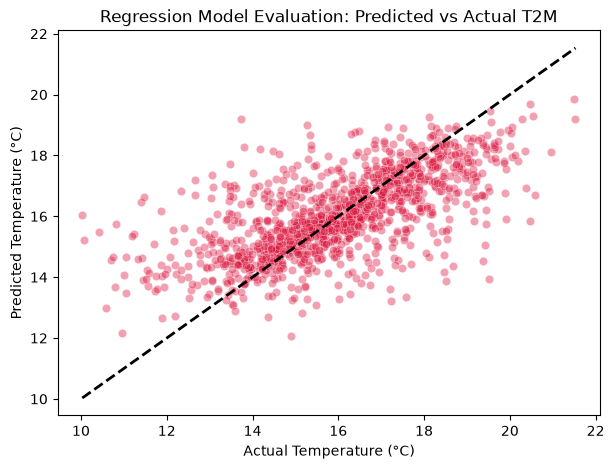

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# We use plt.scatter() in order to visualize how tightly clustered the predicted temperatures are against the actual temperatures
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.4, color="crimson")

# Draw a diagonal line showing perfect 1-to-1 match predictions
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)

plt.title("Regression Model Evaluation: Predicted vs Actual T2M")
plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.show()
